# E.2 Sickle-cell trait and genotype-specific fitness

The HbS allele can cause severe sickle-cell disease in homozygotes, while heterozygotes can have protection against severe falciparum malaria. How can the same allele be maintained?

Let $p$ be the HbS frequency and $q=1-p$. The HWE frequencies of $AA$, $AS$, and $SS$ are $q^2$, $2pq$, and $p^2$. With relative fitnesses $w_{AA}$, $w_{AS}$, and $w_{SS}$, the expected HbS frequency after selection is

$$p_s=\frac{p^2w_{SS}+pqw_{AS}}{q^2w_{AA}+2pqw_{AS}+p^2w_{SS}}.$$

Fitness depends on genotype and environment. The numerical values below are teaching values, not estimates for any population. This notebook has no migration and does not solve the two-region Homework 11.


## Predict an internal equilibrium

In a malaria-endemic setting, set $(w_{AA},w_{AS},w_{SS})=(0.92,1,0.25)$. When HbS is rare, most copies are in $AS$ heterozygotes and should increase. As $p$ rises, costly $SS$ genotypes become more common. Under this idealized overdominance model, the equilibrium is $p^*=(1-w_{AA})/[(1-w_{AA})+(1-w_{SS})]$.


In [1]:
library(hpgR)

malaria <- c(AA = 0.92, AS = 1, SS = 0.25)
no_malaria <- c(AA = 1, AS = 0.98, SS = 0.25)
equilibrium <- (1 - malaria['AA']) /
  ((1 - malaria['AA']) + (1 - malaria['SS']))
stopifnot(abs(selectedFrequency(equilibrium, rev(malaria)) - equilibrium) < 1e-12)
c(start = 0.02, malaria_equilibrium = equilibrium)

start malaria_equilibrium.AA 
            0.02000000             0.09638554

## Change the environment, not the starting allele

Start both settings at $p_0=0.02$. The second illustrative fitness vector gives $AA$ the highest fitness. We expect HbS to rise toward an internal equilibrium in the first setting and decline in the second. These are expected paths without drift, migration, or changing malaria prevalence.


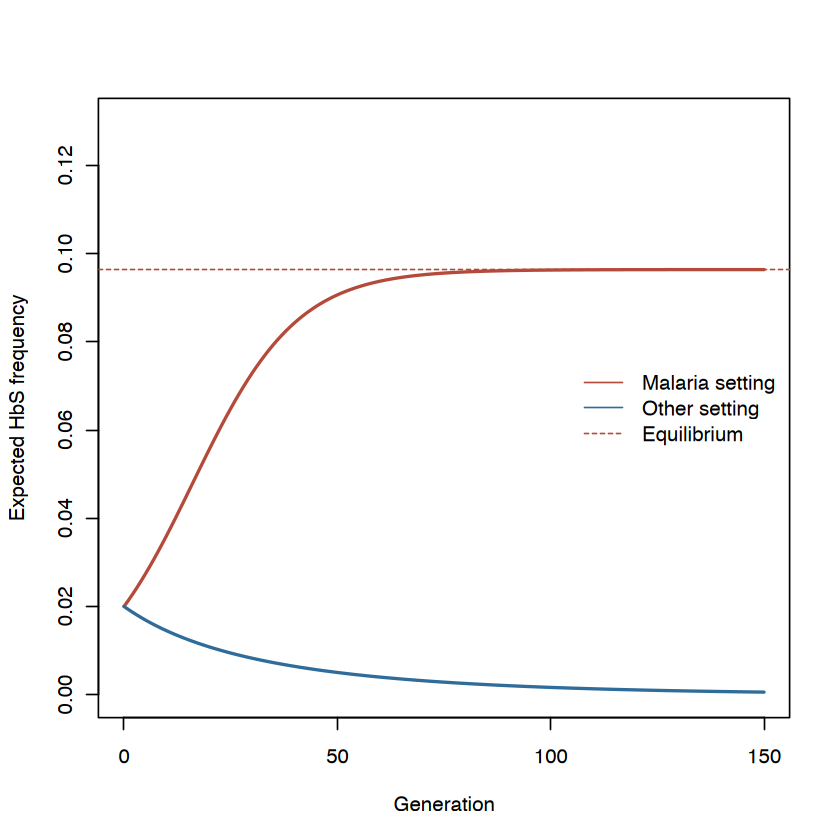

In [2]:
generations <- 150
with_malaria <- selectionFrequencies(0.02, rev(malaria), generations)
without_malaria <- selectionFrequencies(0.02, rev(no_malaria), generations)
plot(0:generations, with_malaria, type = 'l', lwd = 2, col = '#B44A3A',
     ylim = c(0, 0.13), xlab = 'Generation', ylab = 'Expected HbS frequency')
lines(0:generations, without_malaria, lwd = 2, col = '#306C9A')
abline(h = equilibrium, lty = 2, col = '#B44A3A')
legend('right', c('Malaria setting', 'Other setting', 'Equilibrium'),
       col = c('#B44A3A', '#306C9A', '#B44A3A'), lty = c(1, 1, 2), bty = 'n')
stopifnot(with_malaria[2] > with_malaria[1])
stopifnot(without_malaria[2] < without_malaria[1])

## What to remember

A genotype-specific fitness model can maintain both alleles when heterozygotes have the highest fitness. Changing the environment changes that comparison. A real HbS frequency also depends on migration, drift, malaria exposure, treatment, and population history; the curve alone does not estimate those effects.

**Sources.** Pritchard, *An Owner's Guide to the Human Genome*, Sections 2.5–2.6; Gorroochurn, *Population Genetics Notes*, Sections 5.5–5.7; Allison (1954) for the malaria association. The two fitness vectors are original teaching values, distinct from Homework 11; no real population's frequency is fitted here.
